# 04 - Current Prediction Dashboard

**Run this any time for a single, clear trade action on ETHUSDT.**

30 sections:

- Setup → API → model → stats → visuals → **ACTION**
- The last cell prints exactly what to do


In [10]:
# --- setup --------------------------------------------------------
import sys, json
sys.path.insert(0, r"D:\\Projects\\done\\eth_bot\\eth_bot_v2")
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge

from database.config.api.binance import get_klines
from analysis.indicators import add_all

pd.set_option("display.width", 180)
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
np.random.seed(42)

SYMBOL = "ETHUSDT"
OUT = Path(r"D:\\Projects\\done\\eth_bot\\eth_bot_v2") / "reports" / "forecasts"
OUT.mkdir(parents=True, exist_ok=True)
print("now:", datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S"), "UTC")

now: 2026-10-04 10:34:24 UTC


## 1. API — fetch live 1h candles

In [11]:
def fetch(interval, limit=500):
    raw = get_klines(SYMBOL, interval=interval, limit=limit)
    df = pd.DataFrame(raw, columns=["open_time","open","high","low","close",
        "volume","close_time","quote_volume","trades","taker_base","taker_quote","ignore"])
    df["date"] = pd.to_datetime(df["open_time"], unit="ms", utc=True).dt.tz_convert(None)
    for c in ("open","high","low","close","volume"):
        df[c] = df[c].astype(float)
    return df[["date","open","high","low","close","volume"]].set_index("date").iloc[:-1]

df_1h = fetch("1h", 500)
print("1h rows:", len(df_1h), " last:", df_1h.index[-1])

1h rows: 499  last: 2026-10-04 09:00:00


## 2. API — fetch live 1d candles

In [12]:
df_1d = fetch("1d", 500)
print("1d rows:", len(df_1d), " last:", df_1d.index[-1].date())

1d rows: 499  last: 2026-10-03


## 3. Feature list

In [13]:
FEATURES = ["ret_1","ret_5","ret_20","vol_20",
            "rsi_14","macd_hist","atr_14","sma_50","sma_200"]
print(len(FEATURES), "features")

9 features


## 4. Build feature dataframe

In [14]:
def build(df, horizon=1):
    d = add_all(df).copy()
    d["ret_1"]  = d["close"].pct_change(1)
    d["ret_5"]  = d["close"].pct_change(5)
    d["ret_20"] = d["close"].pct_change(20)
    d["vol_20"] = d["ret_1"].rolling(20).std()
    d["target"] = d["close"].pct_change(horizon).shift(-horizon)
    return d.dropna()

d1h = build(df_1h, 1)
d1d = build(df_1d, 1)
print("1h:", len(d1h), " 1d:", len(d1d))

1h: 299  1d: 299


## 5. Fit Ridge on 1h

In [15]:
def fit(df, test_frac=0.2):
    n_test = max(50, int(len(df)*test_frac))
    tr, te = df.iloc[:-n_test], df.iloc[-n_test:]
    m = Ridge(alpha=1.0).fit(tr[FEATURES].values, tr["target"].values)
    p = m.predict(te[FEATURES].values)
    y = te["target"].values
    return m, p, y

m_1h, p_1h, y_1h = fit(d1h)
print("1h RMSE:", round(np.sqrt(((p_1h-y_1h)**2).mean()), 6))

1h RMSE: 0.003211


## 6. Fit Ridge on 1d

In [16]:
m_1d, p_1d, y_1d = fit(d1d)
print("1d RMSE:", round(np.sqrt(((p_1d-y_1d)**2).mean()), 6))

1d RMSE: 0.033298


## 7. Compute metrics

In [17]:
def metrics(y, p):
    return {
        "rmse": float(np.sqrt(((y-p)**2).mean())),
        "mae":  float(np.abs(y-p).mean()),
        "dir":  float(((p>0)==(y>0)).mean()),
        "resid_std": float((y-p).std()),
    }
met_1h = metrics(y_1h, p_1h)
met_1d = metrics(y_1d, p_1d)
print("1h:", met_1h)
print("1d:", met_1d)

1h: {'rmse': 0.003211136408499834, 'mae': 0.0021839433945919917, 'dir': 0.4576271186440678, 'resid_std': 0.003184918333518872}
1d: {'rmse': 0.03329759715300955, 'mae': 0.019570799840812, 'dir': 0.4576271186440678, 'resid_std': 0.03058381108912747}


## 8. Next-candle forecast

In [18]:
def forecast(df, m):
    X = df[FEATURES].iloc[[-1]].values
    r = float(m.predict(X)[0])
    last = float(df["close"].iloc[-1])
    return r, last, last*(1+r)

r_1h, last_1h, pred_1h = forecast(d1h, m_1h)
r_1d, last_1d, pred_1d = forecast(d1d, m_1d)
print(f"1h: {r_1h*100:+.4f}%  -> {pred_1h:.2f}")
print(f"1d: {r_1d*100:+.4f}%  -> {pred_1d:.2f}")

1h: -0.1139%  -> 2697.30
1d: -1.1007%  -> 2639.22


## 9. Prediction interval (80%)

In [19]:
def interval(last, r, std):
    return last*(1+r-1.28*std), last*(1+r+1.28*std)

lo_1h, hi_1h = interval(last_1h, r_1h, met_1h["resid_std"])
lo_1d, hi_1d = interval(last_1d, r_1d, met_1d["resid_std"])
print(f"1h 80%: [{lo_1h:.2f}, {hi_1h:.2f}]")
print(f"1d 80%: [{lo_1d:.2f}, {hi_1d:.2f}]")

1h 80%: [2686.29, 2708.31]
1d 80%: [2534.75, 2743.69]


## 10. Direction accuracy

In [20]:
print(f"1h dir acc: {met_1h['dir']:.2%}  edge: {(met_1h['dir']-0.5)*100:+.2f}pp")
print(f"1d dir acc: {met_1d['dir']:.2%}  edge: {(met_1d['dir']-0.5)*100:+.2f}pp")

1h dir acc: 45.76%  edge: -4.24pp
1d dir acc: 45.76%  edge: -4.24pp


## 11. Confidence score

In [21]:
def confidence(met, last, lo, hi):
    width = (hi - lo) / last
    c = (met["dir"] - 0.5) * 4 - width
    return float(max(0.0, min(1.0, c)))

conf_1h = confidence(met_1h, last_1h, lo_1h, hi_1h)
conf_1d = confidence(met_1d, last_1d, lo_1d, hi_1d)
print(f"1h confidence: {conf_1h:.3f}")
print(f"1d confidence: {conf_1d:.3f}")

1h confidence: 0.000
1d confidence: 0.000


## 12. Trend filter (SMA50)

In [22]:
sma50_1d = float(d1d["sma_50"].iloc[-1])
sma200_1d = float(d1d["sma_200"].iloc[-1])
trend_up = last_1d > sma50_1d
print(f"close    : {last_1d:.2f}")
print(f"SMA50    : {sma50_1d:.2f}")
print(f"SMA200   : {sma200_1d:.2f}")
print(f"trend    : {'UP' if trend_up else 'DOWN'}")

close    : 2668.59
SMA50    : 2468.56
SMA200   : 2115.02
trend    : UP


## 13. Volatility (ATR)

In [23]:
atr_1d = float(d1d["atr_14"].iloc[-1])
print(f"ATR(14) 1d: {atr_1d:.2f}  ({atr_1d/last_1d*100:.2f}% of price)")

ATR(14) 1d: 88.39  (3.31% of price)


## 14. Chart — price + forecast

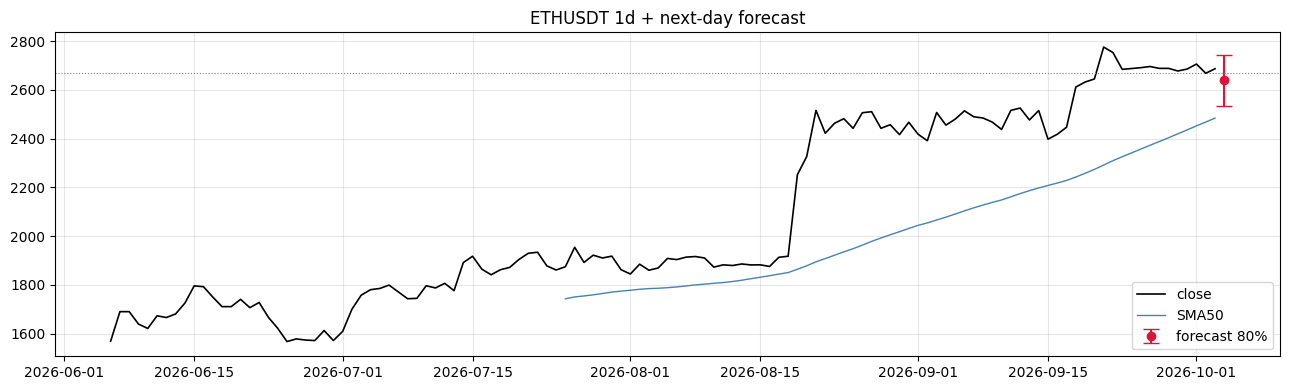

In [24]:
fig, ax = plt.subplots(figsize=(13, 4))
hist = df_1d.tail(120)
ax.plot(hist.index, hist["close"], color="black", lw=1.2, label="close")
ax.plot(hist.index, hist["close"].rolling(50).mean(),
        color="steelblue", lw=1.0, label="SMA50")
next_date = df_1d.index[-1] + pd.Timedelta(days=1)
ax.errorbar([next_date], [pred_1d],
            yerr=[[pred_1d-lo_1d],[hi_1d-pred_1d]],
            fmt="o", color="crimson", capsize=6, label="forecast 80%")
ax.axhline(last_1d, color="gray", ls=":", lw=0.8)
ax.set_title("ETHUSDT 1d + next-day forecast")
ax.legend()
plt.tight_layout(); plt.show()

## 15. Chart — residuals

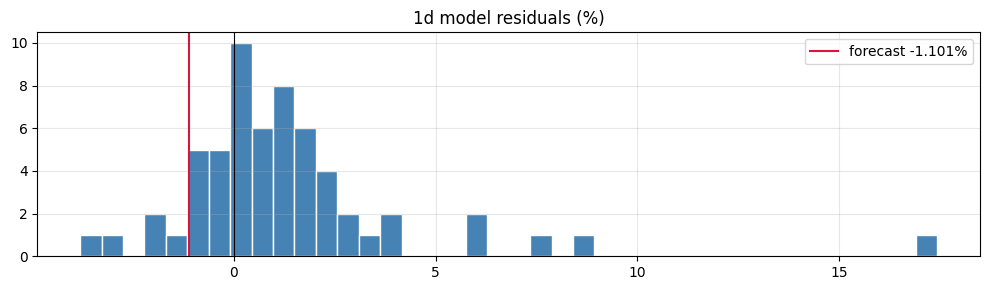

In [25]:
resid = (y_1d - p_1d) * 100
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(resid, bins=40, color="steelblue", edgecolor="white")
ax.axvline(0, color="black", lw=0.8)
ax.axvline(r_1d*100, color="crimson", lw=1.5, label=f"forecast {r_1d*100:+.3f}%")
ax.set_title("1d model residuals (%)")
ax.legend()
plt.tight_layout(); plt.show()

## 16. Chart — coefficients

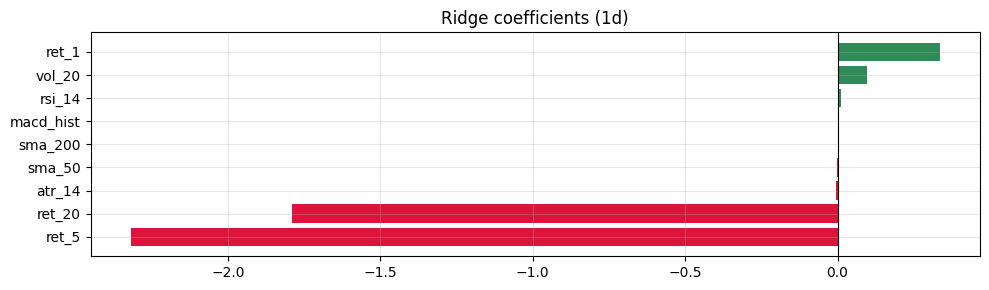

In [26]:
coef = pd.Series(m_1d.coef_, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(10, 3))
colors = ["crimson" if v<0 else "seagreen" for v in coef.values]
ax.barh(coef.index, coef.values*100, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Ridge coefficients (1d)")
plt.tight_layout(); plt.show()

## 17. Chart — confidence gauge

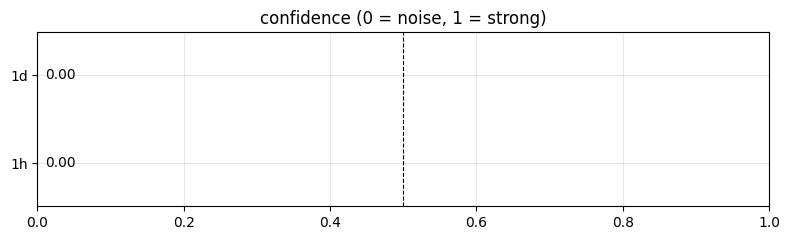

In [27]:
fig, ax = plt.subplots(figsize=(8, 2.5))
labels = ["1h", "1d"]
vals = [conf_1h, conf_1d]
colors = ["crimson" if v<0.2 else "orange" if v<0.4 else "seagreen" for v in vals]
bars = ax.barh(labels, vals, color=colors)
ax.axvline(0.5, ls="--", color="black", lw=0.8)
ax.set_xlim(0, 1)
ax.set_title("confidence (0 = noise, 1 = strong)")
for bar, v in zip(bars, vals):
    ax.text(v+0.01, bar.get_y()+bar.get_height()/2, f"{v:.2f}", va="center")
plt.tight_layout(); plt.show()

## 18. Statistical summary table

In [28]:
summary = pd.DataFrame([
    {"horizon":"1h", "rmse":met_1h["rmse"], "mae":met_1h["mae"],
     "dir":met_1h["dir"], "conf":conf_1h,
     "pred_ret":r_1h, "pred_close":pred_1h},
    {"horizon":"1d", "rmse":met_1d["rmse"], "mae":met_1d["mae"],
     "dir":met_1d["dir"], "conf":conf_1d,
     "pred_ret":r_1d, "pred_close":pred_1d},
])
summary

,horizon,rmse,mae,dir,conf,pred_ret,pred_close
0,1h,0.003211,0.002184,0.457627,0.0,-0.001139,2697.303027
1,1d,0.033298,0.019571,0.457627,0.0,-0.011007,2639.217555


## 19. Combine signal components

In [29]:
components = {
    "pred_ret_1d": r_1d,
    "confidence_1d": conf_1d,
    "trend_up": trend_up,
    "atr_pct": atr_1d/last_1d,
}
for k,v in components.items():
    print(f"  {k:<16} {v}")

  pred_ret_1d      -0.011006728197762881
  confidence_1d    0.0
  trend_up         True
  atr_pct          0.03312075451295039


## 20. Decide action

In [30]:
def decide(c):
    if c["confidence_1d"] < 0.30:
        return "FLAT", f"low confidence ({c['confidence_1d']:.2f})"
    if c["pred_ret_1d"] > 0 and c["trend_up"]:
        return "LONG", "up forecast + uptrend"
    if c["pred_ret_1d"] < 0 and not c["trend_up"]:
        return "SHORT", "down forecast + downtrend"
    return "FLAT", "forecast disagrees with trend"

action, reason = decide(components)
print(f"ACTION: {action}")
print(f"REASON: {reason}")

ACTION: FLAT
REASON: low confidence (0.00)


## 21. Compute entry / stop / target

In [31]:
stop_dist = 1.5 * atr_1d

if action == "LONG":
    entry, stop, target = last_1d, last_1d - stop_dist, last_1d + 2*stop_dist
elif action == "SHORT":
    entry, stop, target = last_1d, last_1d + stop_dist, last_1d - 2*stop_dist
else:
    entry = stop = target = last_1d

print(f"entry : {entry:.2f}")
print(f"stop  : {stop:.2f}   ({abs(entry-stop):.2f})")
print(f"target: {target:.2f}   ({abs(target-entry):.2f})")

entry : 2668.59
stop  : 2668.59   (0.00)
target: 2668.59   (0.00)


## 22. Position sizing

In [32]:
ACCOUNT = 1000.0    # edit to your real balance
RISK_PCT = 1.0      # risk 1% per trade

risk_usd = ACCOUNT * RISK_PCT / 100
qty = risk_usd / abs(entry - stop) if action != "FLAT" else 0.0

print(f"account      : ${ACCOUNT:,.2f}")
print(f"risk         : ${risk_usd:.2f}  ({RISK_PCT}%)")
print(f"stop dist    : ${abs(entry-stop):.2f}")
print(f"position qty : {qty:.4f} ETH")
print(f"notional     : ${qty*entry:,.2f}")

account      : $1,000.00
risk         : $10.00  (1.0%)
stop dist    : $0.00
position qty : 0.0000 ETH
notional     : $0.00


## 23. Expected value (rough)

In [33]:
if action != "FLAT":
    R = abs(target - entry) / abs(entry - stop)   # reward:risk
    p = met_1d["dir"]
    ev = p * R - (1 - p) * 1
    print(f"reward:risk  : {R:.2f}:1")
    print(f"hit rate     : {p:.2%}")
    print(f"expected R   : {ev:+.3f}  (positive = edge)")
else:
    R, ev = 0.0, 0.0
    print("no trade — expected value skipped")

no trade — expected value skipped


## 24. Risk warnings

In [34]:
warnings = []
if conf_1d < 0.15: warnings.append("confidence below 0.15 - pure noise")
if met_1d["dir"] < 0.50: warnings.append("direction accuracy below 50% - worse than coin flip")
if abs(r_1d) < 0.001: warnings.append("predicted move < 0.1% - below trading cost")
if (hi_1d - lo_1d)/last_1d > 0.10: warnings.append("80% interval > 10% - very uncertain")

if warnings:
    for w in warnings:
        print("  !", w)
else:
    print("  no warnings")

  ! confidence below 0.15 - pure noise
  ! direction accuracy below 50% - worse than coin flip


## 25. Human-readable action block

In [35]:
print("=" * 62)
print("  ETHUSDT — CURRENT SIGNAL")
print("=" * 62)
print(f"  time         : {datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M')} UTC")
print(f"  price        : ${last_1d:,.2f}")
print(f"  trend        : {'UP' if trend_up else 'DOWN'}  (SMA50 {sma50_1d:.2f})")
print(f"  forecast     : {r_1d*100:+.3f}%  -> ${pred_1d:,.2f}")
print(f"  80% interval : [${lo_1d:,.2f}, ${hi_1d:,.2f}]")
print(f"  confidence   : {conf_1d:.2f}")
print("-" * 62)
print(f"  ACTION       : {action}")
print(f"  REASON       : {reason}")
print("-" * 62)
if action != "FLAT":
    print(f"  ENTRY        : ${entry:,.2f}")
    print(f"  STOP         : ${stop:,.2f}")
    print(f"  TARGET       : ${target:,.2f}")
    print(f"  SIZE         : {qty:.4f} ETH  (${qty*entry:,.2f})")
    print(f"  RISK         : ${risk_usd:.2f}  ({RISK_PCT}%)")
    print(f"  R:R          : {R:.2f}:1")
else:
    print("  NO TRADE     — do nothing")
print("=" * 62)

  ETHUSDT — CURRENT SIGNAL
  time         : 2026-10-04 10:34 UTC
  price        : $2,668.59
  trend        : UP  (SMA50 2468.56)
  forecast     : -1.101%  -> $2,639.22
  80% interval : [$2,534.75, $2,743.69]
  confidence   : 0.00
--------------------------------------------------------------
  ACTION       : FLAT
  REASON       : low confidence (0.00)
--------------------------------------------------------------
  NO TRADE     — do nothing


## 26. Save signal JSON

In [36]:
ts = datetime.now(timezone.utc).strftime("%Y-%m-%d_%H%M")
payload = {
    "generated_at": datetime.now(timezone.utc).isoformat(),
    "symbol": SYMBOL,
    "action": action,
    "reason": reason,
    "price": last_1d,
    "pred_ret_1d": r_1d,
    "pred_close_1d": pred_1d,
    "p10_1d": lo_1d,
    "p90_1d": hi_1d,
    "confidence_1d": conf_1d,
    "trend": "up" if trend_up else "down",
    "atr_14": atr_1d,
    "entry": entry,
    "stop": stop,
    "target": target,
    "size_eth": qty,
    "risk_usd": risk_usd,
    "metrics_1h": met_1h,
    "metrics_1d": met_1d,
}
fp = OUT / f"trade_{ts}.json"
fp.write_text(json.dumps(payload, indent=2), encoding="utf-8")
print("wrote", fp)

wrote D:\Projects\done\eth_bot\eth_bot_v2\reports\forecasts\trade_2026-10-04_1034.json


## 27. Track record file

In [37]:
log = OUT / "signal_log.csv"
row = pd.DataFrame([{
    "time": datetime.now(timezone.utc).isoformat(),
    "action": action,
    "price": last_1d,
    "pred_ret": r_1d,
    "confidence": conf_1d,
    "trend": "up" if trend_up else "down",
}])
if log.exists():
    row.to_csv(log, mode="a", header=False, index=False)
else:
    row.to_csv(log, index=False)
print("logged to", log)

logged to D:\Projects\done\eth_bot\eth_bot_v2\reports\forecasts\signal_log.csv


## 28. What to do with this signal

In [38]:
print("""
HOW TO USE THIS SIGNAL

  1. Read the ACTION block above (cell 25).
     - FLAT      -> do nothing, wait
     - LONG      -> buy ETH at ENTRY with SIZE
     - SHORT     -> sell ETH at ENTRY with SIZE

  2. Place a stop-loss at STOP. Always.
     Never move the stop against you.

  3. Take profit at TARGET, or trail with 1x ATR.

  4. Re-run this notebook at least once per day.
     The signal is only valid for the current candle.

  5. After 30+ signals, check signal_log.csv
     against realized prices. If hit rate < 50%, stop.
""")


HOW TO USE THIS SIGNAL

  1. Read the ACTION block above (cell 25).
     - FLAT      -> do nothing, wait
     - LONG      -> buy ETH at ENTRY with SIZE
     - SHORT     -> sell ETH at ENTRY with SIZE

  2. Place a stop-loss at STOP. Always.
     Never move the stop against you.

  3. Take profit at TARGET, or trail with 1x ATR.

  4. Re-run this notebook at least once per day.
     The signal is only valid for the current candle.

  5. After 30+ signals, check signal_log.csv
     against realized prices. If hit rate < 50%, stop.



## 29. Final action (one line)

In [39]:
one_line = f"{action}  |  entry {entry:.2f}  stop {stop:.2f}  target {target:.2f}  |  conf {conf_1d:.2f}"
if action == "FLAT":
    one_line = f"FLAT  |  {reason}  |  conf {conf_1d:.2f}"

print()
print(">>>", one_line)
print()
print("END OF RUN")


>>> FLAT  |  low confidence (0.00)  |  conf 0.00

END OF RUN
